# Part 2: Bayesian Probability on IMDb Reviews

**Our choice:** We calculate **P(Positive | keyword)** only, not P(Negative | keyword).

**Dataset:** 50,000 IMDb reviews, half positive and half negative, so the prior P(Positive) = 0.5.

**Method (basic Python only):** For each keyword we compute
- **Prior:** positive reviews / all reviews
- **Likelihood:** positive reviews with the word / positive reviews
- **Marginal:** reviews with the word / all reviews
- **Posterior:** Likelihood x Prior / Marginal (Bayes' theorem)

**Keywords and why:**
- **Positive:** excellent, wonderful, amazing (direct praise) and great (very common, so we test if a popular word is also reliable).
- **Negative:** terrible, awful (direct criticism), boring (a common reason for a bad review) and worst (used in extreme complaints).




In [4]:
import csv
import re

def load(path):
    reviews = []
    with open(path, encoding="utf-8") as f:
        rows = csv.reader(f)
        next(rows)  # skip the header
        for text, label in rows:
            words = set(re.findall(r"[a-z']+", text.lower()))
            reviews.append((words, label))
    return reviews

reviews = load("/content/IMDB Dataset.csv")
print(len(reviews), "reviews loaded")

50000 reviews loaded


# New Section

In [5]:
def bayes(reviews, word):
    total = len(reviews)
    pos = sum(1 for words, label in reviews if label == "positive")
    has = sum(1 for words, label in reviews if word in words)
    has_pos = sum(1 for words, label in reviews if word in words and label == "positive")

    prior = pos / total                         # P(Positive)
    likelihood = has_pos / pos                  # P(word | Positive)
    marginal = has / total                      # P(word)
    posterior = likelihood * prior / marginal   # Bayes' theorem
    return prior, likelihood, marginal, posterior

In [6]:
keywords = ["excellent", "wonderful", "amazing", "great",
            "terrible", "awful", "boring", "worst"]

print(f"{'word':<11}{'prior':>7}{'likelihood':>12}{'marginal':>10}{'posterior':>11}")
for word in keywords:
    prior, likelihood, marginal, posterior = bayes(reviews, word)
    print(f"{word:<11}{prior:>7.4f}{likelihood:>12.4f}{marginal:>10.4f}{posterior:>11.4f}")

word         prior  likelihood  marginal  posterior
excellent   0.5000      0.1146    0.0710     0.8073
wonderful   0.5000      0.0902    0.0555     0.8120
amazing     0.5000      0.0671    0.0431     0.7783
great       0.5000      0.3387    0.2512     0.6741
terrible    0.5000      0.0152    0.0539     0.1413
awful       0.5000      0.0112    0.0575     0.0977
boring      0.5000      0.0236    0.0610     0.1938
worst       0.5000      0.0164    0.0886     0.0924


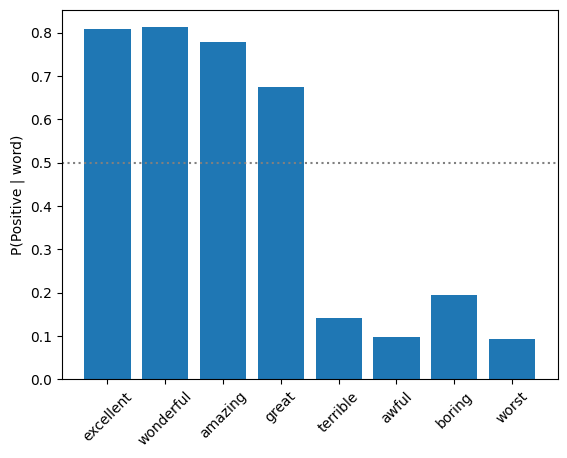

In [7]:
import matplotlib.pyplot as plt

posteriors = [bayes(reviews, w)[3] for w in keywords]
plt.bar(keywords, posteriors)
plt.axhline(0.5, color="grey", linestyle=":")
plt.ylabel("P(Positive | word)")
plt.xticks(rotation=45)
plt.show()

## What our results show
- **wonderful (0.81)** and **excellent (0.81)** are our strongest positive signals.
- **worst (0.09)** and **awful (0.10)** are our strongest negative signals. A review containing "worst" is only about 9% likely to be positive.
- **great (0.67)** is our weakest positive word. It appears in about 25% of all reviews, including many negative ones, so it is a weaker clue than its popularity suggests.
- All four positive keywords have a posterior above the 0.5 prior, and all four negative keywords have a posterior far below it. This supports our keyword choices.